In [ ]:
from transformers import AutoTokenizer
import torch 
import numpy as np
import pickle
import os
import re
import glob
import string
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.notebook import tqdm
import seaborn as sns
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.stats import multitest
import statsmodels.api as sm
import pingouin as pg
import sys
sys.path.append('..')
from utils import get_segmentation_indices,segmentation_to_word_list
from utils import calculate_cross_entropy,normalize_entropy,model_to_path_dict

In [3]:
stories = ['pieman','alternateithicatom','odetostepfather','souls','legacy','wheretheressmoke','adventuresinsayingyes','inamoment']
story_to_idx_mapping = {s:stories.index(s)+1 for s in stories}

In [4]:
plotting_label_dict_sm = {
    "weighted_event_info_by_duration": "CRUISE", 
    "weighted_event_info_conditioned": "Surprisal-weighted sampling",
    'H_event_conditioned': "Surprisal",
    'H_event': "Total information",
    'event_duration': "Duration",
    "event_len": "Number of tokens",
    "event_kl":"Relative entropy",
    "sylber_ce":"Acoustic surprisal",
    "weighted_event_info_sylber_ce": "Acoustic surprisal-weighted sampling",
    "weighted_event_info_kl":"KL-weighted sampling", 
    "weighted_event_info_exponential_saturation":"CRUISE (Saturation)",
    "seg_prop":'P(Segmentation)'
}

In [5]:
uniform_preds = ['weighted_event_info_by_duration','weighted_event_info_exponential_saturation','weighted_event_info','weighted_event_info_conditioned','weighted_event_info_kl','weighted_event_info_sylber_ce']
controls = ['H_event_conditioned','H_event','event_kl','event_len','event_duration','sylber_ce']
uniform_preds_punctuated = uniform_preds +['weighted_event_info_conditioned_punctuated','weighted_event_info_kl_punctuated']
controls_punctuated = controls +['event_kl_punctuated','event_surprisal_punctuated']

all_preds = uniform_preds+controls
all_preds_main = ['weighted_event_info_by_duration','weighted_event_info_conditioned']+controls
uniform_preds_colors = {p:sns.color_palette("light:#005F5F_r", len(uniform_preds)+1)[i] for i,p in enumerate(uniform_preds)}
controls_colors= {p:sns.color_palette("light:#FFBF00", len(controls)+1)[i+1] for i,p in enumerate(controls)}
all_colors = {**uniform_preds_colors, **controls_colors}
all_colors.update({'chunk_type': "#ad8ec0"})

In [6]:
BASE_DIR = '../..'
save_dir = os.path.join(BASE_DIR,'generated')
sr_save_dir = os.path.join(BASE_DIR,'exp2','generated')
model_name = 'Llama3-8b-instruct'
factor = 1.5
model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
fig_dir = os.path.join(sr_save_dir,model_save_dir_name,'figures','segmentation')
if not os.path.exists(fig_dir):
    os.makedirs(fig_dir)
plot_fontsize = 9

In [7]:
# proportion of segmenting after each word
original_exp_dir = os.path.join(BASE_DIR,'behavior_data','segmentation')
sr_exp_dir = os.path.join(BASE_DIR,'exp2','behavior_data','segmentation')
corr_df = []
for story in stories:
    with open(os.path.join(original_exp_dir,story,'%s_segmentation_prop.pkl'%story),'rb') as f:
        original_exp_prop = pickle.load(f)
    with open(os.path.join(sr_exp_dir,story,'original','%s_segmentation_prop.pkl'%story),'rb') as f:
        sr_exp_original_prop = pickle.load(f)
    with open(os.path.join(sr_exp_dir,story,'shrink','%s_segmentation_prop.pkl'%story),'rb') as f:
        sr_exp_shrink_prop = pickle.load(f)
    if story=='adventuresinsayingyes' or story=='inamoment': # the new version of timing got rid of the first empty string. everything else is the same
        original_exp_prop = original_exp_prop[1:]
    assert len(original_exp_prop)==len(sr_exp_original_prop)==len(sr_exp_shrink_prop)
    
    original_to_original_corr = np.corrcoef(original_exp_prop,sr_exp_original_prop)[0,1]
    original_to_shrink_corr = np.corrcoef(original_exp_prop,sr_exp_shrink_prop)[0,1]
    sr_original_to_shrink_corr = np.corrcoef(sr_exp_original_prop,sr_exp_shrink_prop)[0,1]
    corr_df.append([original_to_original_corr,original_to_shrink_corr,sr_original_to_shrink_corr,'Story '+str(story_to_idx_mapping[story])])
corr_df = pd.DataFrame(corr_df, columns = ['Original audio, Exp 1 vs. Exp 2','Original audio, Exp 1 vs. Shrink','Original audio, Exp 2 vs. Shrink','story_idx']) 

In [8]:
from itertools import product, combinations
from scipy.stats import false_discovery_control

value_cols = [c for c in corr_df.columns if c != "story_idx"]

def exact_sign_flip_test(d):
    """Exact paired sign-flip test on differences d. Returns (mean diff, two-sided p)."""
    d = np.asarray(d, dtype=float); n = len(d)
    obs = d.mean()
    signs = np.array(list(product([1, -1], repeat=n)))
    stats = (signs * d).mean(axis=1)
    return obs, np.mean(np.abs(stats) >= np.abs(obs) - 1e-12)

# Fisher z since these are Pearson r
z = {c: np.arctanh(corr_df[c].values) for c in value_cols}
pairs = list(combinations(value_cols, 2))

rows = []
for a, b in pairs:
    obs_r, _ = exact_sign_flip_test(corr_df[a].values - corr_df[b].values)
    _, p_z   = exact_sign_flip_test(z[a] - z[b])
    rows.append({"col A": a, "col B": b, "mean diff (r)": obs_r, "p (Fisher z)": p_z})

res = pd.DataFrame(rows)
res["p_fdr (BH)"] = false_discovery_control(res["p (Fisher z)"].values, method="bh")
print(res.to_string(index=False))

                           col A                            col B  mean diff (r)  p (Fisher z)  p_fdr (BH)
 Original audio, Exp 1 vs. Exp 2 Original audio, Exp 1 vs. Shrink       0.314539      0.007812    0.011719
 Original audio, Exp 1 vs. Exp 2 Original audio, Exp 2 vs. Shrink       0.284687      0.007812    0.011719
Original audio, Exp 1 vs. Shrink Original audio, Exp 2 vs. Shrink      -0.029852      0.054688    0.054688


In [9]:
long_corr_df = corr_df.melt(
    id_vars="story_idx",
    var_name="condition",
    value_name="value"
)

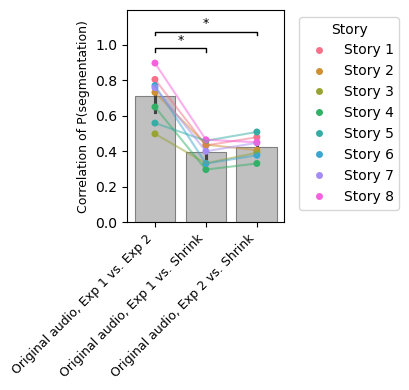

In [10]:
fig,ax = plt.subplots(figsize=(4,4))
g = sns.barplot(
    data=long_corr_df,
    x="condition",
    y="value",
    color='#C0C0C0', edgecolor='#808080', linewidth=0.8, zorder=1
)

sns.stripplot(
    data=long_corr_df,
    x="condition",
    y="value",
    hue="story_idx",
    jitter=False,
    dodge=False,
    palette = sns.color_palette("husl",len(stories)),
)


sns.lineplot(
    data=long_corr_df,
    x="condition",
    y="value",
    units="story_idx",
    hue="story_idx",
    estimator=None,
    linewidth=1.5,
    legend=False,
    zorder=3,
    palette = sns.color_palette("husl",len(stories)),
    alpha = 0.5
)

# Annotate significant pairwise sign-flip tests after FDR correction
def p_to_stars(p):
    if p < 0.001:
        return '***'
    if p < 0.01:
        return '**'
    if p < 0.05:
        return '*'
    return 'ns'

condition_positions = {condition: i for i, condition in enumerate(value_cols)}
sig_results = res.loc[res['p_fdr (BH)'] < 0.05].copy()
sig_results['span'] = sig_results.apply(
    lambda row: abs(condition_positions[row['col B']] - condition_positions[row['col A']]),
    axis=1,
)
sig_results = sig_results.sort_values('span')

ymin, ymax = ax.get_ylim()
y_range = ymax - ymin
bracket_height = 0.02 * y_range
bracket_spacing = 0.10 * y_range
text_offset = 0.01 * y_range
first_bracket_y = ymax + 0.02 * y_range

for level, (_, row) in enumerate(sig_results.iterrows()):
    x1 = condition_positions[row['col A']]
    x2 = condition_positions[row['col B']]
    x1, x2 = sorted((x1, x2))
    y = first_bracket_y + level * bracket_spacing
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + bracket_height, y + bracket_height, y],
        color='black', linewidth=1, clip_on=False, zorder=5,
    )
    ax.text(
        (x1 + x2) / 2, y + bracket_height + text_offset,
        p_to_stars(row['p_fdr (BH)']),
        ha='center', va='bottom', fontsize=plot_fontsize, zorder=5,
    )

if len(sig_results):
    annotation_top = (
        first_bracket_y
        + (len(sig_results) - 1) * bracket_spacing
        + bracket_height
        + text_offset
    )
    ax.set_ylim(ymin, annotation_top + 0.12 * y_range)

plt.legend(title="Story", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xticks(rotation=45, ha="right",fontsize = plot_fontsize)
plt.ylabel('Correlation of P(segmentation)',fontsize = plot_fontsize)
plt.xlabel("")
#plt.title('Correlation of the proportion of segmentation',fontsize = plot_fontsize)
plt.tight_layout()
#fig.savefig(os.path.join(fig_dir,'correlation_proportion_segmentation.svg'),transparent=True)
plt.show()

In [ ]:
distance_df = []
num_seg_df = []
for story in stories:
    with open(os.path.join(original_exp_dir,story,'%s_consensus_wordlist.pkl'%story),'rb') as f:
        original_exp_consensus = pickle.load(f)
    with open(os.path.join(sr_exp_dir,story,'original','%s_consensus_wordlist.pkl'%story),'rb') as f:
        sr_exp_original_consensus = pickle.load(f)
    with open(os.path.join(sr_exp_dir,story,'shrink','%s_consensus_wordlist.pkl'%story),'rb') as f:
        sr_exp_shrink_consensus = pickle.load(f)
    if story=='adventuresinsayingyes' or story=='inamoment': # the new version of timing got rid of the first empty string. everything else is the same
        original_exp_consensus = original_exp_consensus[1:]
    assert len(original_exp_consensus)==len(sr_exp_original_consensus)==len(sr_exp_shrink_consensus)
    
    original_exp_bool = np.array([1 if '\n' in s else 0 for s in original_exp_consensus])
    sr_exp_original_bool = np.array([1 if '\n' in s else 0 for s in sr_exp_original_consensus])
    sr_exp_shrink_bool = np.array([1 if '\n' in s else 0 for s in sr_exp_shrink_consensus])
    
    num_seg_df.append([original_exp_bool.sum(),sr_exp_original_bool.sum(),sr_exp_shrink_bool.sum(),'Story '+str(story_to_idx_mapping[story])])
    
distance_df = pd.DataFrame(distance_df, columns = ['Original audio, Exp 1 vs. Exp 2','Original audio, Exp 1 vs. Shrink','Original audio, Exp 2 vs. Shrink','story_idx']) 
num_seg_df = pd.DataFrame(num_seg_df, columns = ['Original audio, Exp 1','Original audio, Exp 2','Original audio, Shrink','story_idx']) 

In [ ]:
long_num_seg_df = num_seg_df.melt(
    id_vars="story_idx",
    var_name="condition",
    value_name="num_seg"
)

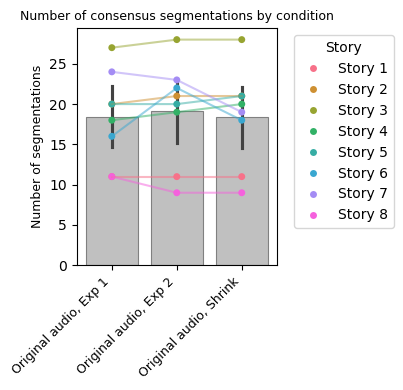

In [14]:
fig,ax = plt.subplots(figsize=(4,4))
g = sns.barplot(
    data=long_num_seg_df,
    x="condition",
    y="num_seg",
    color='#C0C0C0', edgecolor='#808080', linewidth=0.8, zorder=1
)

sns.stripplot(
    data=long_num_seg_df,
    x="condition",
    y="num_seg",
    hue="story_idx",
    jitter=False,
    dodge=False,
    palette = sns.color_palette("husl",len(stories)),
)

sns.lineplot(
    data=long_num_seg_df,
    x="condition",
    y="num_seg",
    units="story_idx",
    hue="story_idx",
    estimator=None,
    linewidth=1.5,
    legend=False,
    zorder=3,
    palette = sns.color_palette("husl",len(stories)),
    alpha = 0.5
)

plt.legend(title="Story", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xticks(rotation=45, ha="right",fontsize = plot_fontsize)
plt.ylabel('Number of segmentations',fontsize = plot_fontsize)
plt.xlabel("")
plt.title('Number of consensus segmentations by condition',fontsize = plot_fontsize)
plt.tight_layout()
#fig.savefig(os.path.join(fig_dir,'num_consensus_segmentations_by_condition.svg'),transparent=True)
plt.show()

## segmentation near deletion windows 

In [15]:
# first figure out which words are near/after deletions 
timing_dir = os.path.join(BASE_DIR,'behavior_data','transcripts','timing')
all_stories_shrunk_around_boundary_rows = {}
all_stories_timing_df_indices_around_shrink = {} # word indices in timing_df
num_words_before_del = 1
num_words_after_del = 3 # 2,3,5,7
for story in stories:
    shrunk_pairwise_event_save_dir = os.path.join(save_dir,model_save_dir_name,'pairwise_event',story,'story_split_tokens_factor_%.1f_adjusted_shrunk'%factor)
    with open(os.path.join(shrunk_pairwise_event_save_dir,'del_nonword_boundary_rows.pkl'),'rb') as f:
        nonword_boundary_rows=pickle.load(f)
    all_stories_shrunk_around_boundary_rows[story] = nonword_boundary_rows
    timing_df = pd.read_csv(os.path.join(timing_dir,'%s_timing.csv'%story))
    
    with open(os.path.join(original_exp_dir,story,'%s_consensus_wordlist.pkl'%story),'rb') as f:
        original_exp_consensus = pickle.load(f)
    if story=='adventuresinsayingyes' or story=='inamoment': # the new version of timing got rid of the first empty string. everything else is the same
        original_exp_consensus = original_exp_consensus[1:]
    # for souls, the timing_df is missing two empty strings. add them in to match the consensus wordlist
    if len(timing_df) != len(original_exp_consensus):
        print(len(timing_df), len(original_exp_consensus))
        empty_string_idx = []
        for i in range(len(original_exp_consensus)):
            if original_exp_consensus[i] =='':
                print(story,i)
                empty_string_idx.append(i)
        for idx in empty_string_idx:
            row = pd.DataFrame({"text": '', "start": np.nan,"stop":np.nan}, index=[idx])
            timing_df = pd.concat([timing_df.iloc[:idx], row, timing_df.iloc[idx:]]).reset_index(drop=True)
    assert len(timing_df) == len(original_exp_consensus)
    
    if story=='pieman':
        timing_df['start']/=1000
        timing_df['stop']/=1000
    
    timing_df_indices_around_shrink = []
    shrink_chunk_len = 0
    for i,row in enumerate(nonword_boundary_rows):
        start_time = row['start']
        stop_time = row['stop']
        if shrink_chunk_len==0:
            chunk_start_time = start_time
        if i <len(nonword_boundary_rows)-1:
            next_start = nonword_boundary_rows[i+1]['start']
            if next_start>stop_time: # next shrink chunk is NOT consecutive, check for words in that window. Else do nothing 
                # let's find a word before and 3 words after?
                rows_before_deletion = np.where(timing_df['start']<chunk_start_time)[0][-num_words_before_del]
                rows_after_deletion = np.where(timing_df['stop']>stop_time)[0][:num_words_after_del]
                timing_df_indices_around_shrink.append(np.concat([[rows_before_deletion],rows_after_deletion]))
                shrink_chunk_len=0
            else:
                shrink_chunk_len+=1
        else:
            rows_before_deletion = np.where(timing_df['start']<chunk_start_time)[0][-num_words_before_del]
            rows_after_deletion = np.where(timing_df['stop']>stop_time)[0][:num_words_after_del]
            timing_df_indices_around_shrink.append(np.concat([[rows_before_deletion],rows_after_deletion]))
    all_stories_timing_df_indices_around_shrink[story] = timing_df_indices_around_shrink
    shrink_indices_save_dir = os.path.join(sr_exp_dir,story,'derived')
    if not os.path.exists(shrink_indices_save_dir):
        os.makedirs(shrink_indices_save_dir)
    with open(os.path.join(shrink_indices_save_dir,'word_indices_-%dto%d_around_shrink.pkl'%(num_words_before_del,num_words_after_del)),'wb') as f:
        pickle.dump(timing_df_indices_around_shrink,f)

1867 1869
souls 455
souls 459


In [16]:
def get_segmentation_prop_around_shrink(story,story_unique_indices,word_id):
    with open(os.path.join(original_exp_dir,story,'%s_segmentation_prop.pkl'%story),'rb') as f:
        original_exp_prop = pickle.load(f)
    with open(os.path.join(sr_exp_dir,story,'original','%s_segmentation_prop.pkl'%story),'rb') as f:
        sr_exp_original_prop = pickle.load(f)
    with open(os.path.join(sr_exp_dir,story,'shrink','%s_segmentation_prop.pkl'%story),'rb') as f:
        sr_exp_shrink_prop = pickle.load(f)
    # match the original exp prop to the new exp
    if story=='adventuresinsayingyes' or story=='inamoment': # the new version of timing got rid of the first empty string. everything else is the same
        original_exp_prop = original_exp_prop[1:]
    
    # the timing_df is matched to the consensus word list, which should be matched to the segmentation prop
    with open(os.path.join(original_exp_dir,story,'%s_consensus_wordlist.pkl'%story),'rb') as f:
        original_exp_consensus = pickle.load(f)
    if story=='adventuresinsayingyes' or story=='inamoment': # the new version of timing got rid of the first empty string. everything else is the same
        original_exp_consensus = original_exp_consensus[1:]
    assert len(original_exp_prop)==len(sr_exp_original_prop)==len(sr_exp_shrink_prop)==len(original_exp_consensus)
    
    values = np.concat([original_exp_prop[story_unique_indices],sr_exp_original_prop[story_unique_indices],sr_exp_shrink_prop[story_unique_indices]])
    conditions = np.concat([['original']*len(story_unique_indices),['sr_original']*len(story_unique_indices),['sr_shrink']*len(story_unique_indices)])
    indices = np.tile(np.arange(word_id,word_id+len(story_unique_indices)),3)
    df = pd.DataFrame({'seg_prop':values,'condition':conditions,'indices':indices,'story':story})
    return df

In [17]:
all_stories_seg_prop_around_shrink = []
word_id = 0
for story in stories:
    timing_df_indices_around_shrink = all_stories_timing_df_indices_around_shrink[story]
    # If the speaker pauses a lot there will be overlapping windows. Get the unique word indices for each story
    story_unique_indices = np.unique(np.concat(timing_df_indices_around_shrink))
    timing_df = pd.read_csv(os.path.join(timing_dir,'%s_timing.csv'%story))
    
    seg_prop_around_shrink_df = get_segmentation_prop_around_shrink(story,story_unique_indices,word_id)
    word_id+=len(seg_prop_around_shrink_df)
    all_stories_seg_prop_around_shrink.append(seg_prop_around_shrink_df)
all_stories_seg_prop_around_shrink = pd.concat(all_stories_seg_prop_around_shrink)

In [18]:
story_stats = (
    all_stories_seg_prop_around_shrink
    .groupby(["story", "condition"])["seg_prop"]
    .agg(mean="mean", se=lambda x: x.std(ddof=1)/np.sqrt(len(x)))
    .reset_index()
)

In [19]:
def get_significance(p_val):
    if p_val < 0.001:
        return "***"
    elif p_val < 0.01:
        return "**"
    elif p_val < 0.05:
        return "*"
    else:
        return "ns"

    Contrast            A            B  Paired  Parametric         T     dof  \
0  condition     original  sr_original    True        True -1.750807  2775.0   
1  condition     original    sr_shrink    True        True  7.621285  2775.0   
2  condition  sr_original    sr_shrink    True        True  8.422023  2775.0   

  alternative         p-unc        p-corr p-adjust       BF10    hedges  
0   two-sided  8.008961e-02  8.008961e-02   fdr_bh      0.099 -0.019970  
1   two-sided  3.424563e-14  5.136845e-14   fdr_bh  6.307e+10  0.184432  
2   two-sided  5.851215e-17  1.755365e-16   fdr_bh  3.336e+13  0.203469  


/tmp/ipykernel_2548805/3735517586.py:196: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


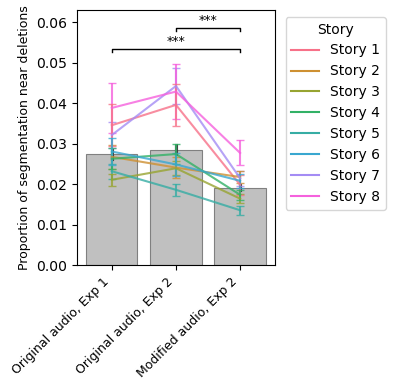

In [20]:
condition_labels = {
    'original': 'Original audio, Exp 1',
    'sr_original': 'Original audio, Exp 2',
    'sr_shrink': 'Modified audio, Exp 2',
}
story_label_order = [f"Story {story_to_idx_mapping[s]}" for s in stories]

all_stories_seg_prop_around_shrink = all_stories_seg_prop_around_shrink.copy()
all_stories_seg_prop_around_shrink['condition_label'] = all_stories_seg_prop_around_shrink['condition'].map(condition_labels)
all_stories_seg_prop_around_shrink['story_label'] = all_stories_seg_prop_around_shrink['story'].map(lambda s: f"Story {story_to_idx_mapping[s]}")

story_stats = (
    all_stories_seg_prop_around_shrink
    .groupby(["story", "story_label", "condition"])["seg_prop"]
    .agg(mean="mean", se=lambda x: x.std(ddof=1)/np.sqrt(len(x)))
    .reset_index()
)
story_stats['condition_label'] = story_stats['condition'].map(condition_labels)

# pairwise tests for significance
pairwise_t = pg.pairwise_tests(data=all_stories_seg_prop_around_shrink, dv='seg_prop', within='condition', subject='indices', padjust='fdr_bh')
print(pairwise_t)
# Palette for stories
palette = sns.color_palette("husl", len(stories))
story_colors = dict(zip(stories, palette))

fig, ax = plt.subplots(figsize=(4, 4))

# Barplot: grand mean per condition
sns.barplot(
    data=all_stories_seg_prop_around_shrink,
    x='condition_label',
    y='seg_prop',
    order=list(condition_labels.values()),
    errorbar='se',
    color='#C0C0C0', edgecolor='#808080', linewidth=0.8, zorder=1,
    ax=ax
)

# Lineplot: story means with hue_order to control legend order
sns.lineplot(
    data=story_stats,
    x='condition_label',
    y='mean',
    units='story_label',
    hue='story_label',
    hue_order=story_label_order,
    estimator=None,
    linewidth=1.5,
    legend=False,
    zorder=3,
    palette=palette,
    alpha=0.8,
    ax=ax
)
legend_handles = [
    plt.Line2D([0], [0], color=palette[i], lw=1.5, label=label)
    for i, label in enumerate(story_label_order)
]
ax.legend(handles=legend_handles, title='Story', bbox_to_anchor=(1.02, 1), loc='upper left')

# Add error bars manually
for story, subdf in story_stats.groupby('story'):
    ax.errorbar(
        subdf['condition_label'],
        subdf['mean'],
        yerr=subdf['se'],
        fmt='none',
        ecolor=story_colors[story],
        capsize=3, alpha=0.8
    )
# Add significance brackets above the bars using the corrected p-values
pval_col = 'p-corr' if 'p-corr' in pairwise_t.columns else 'p_corr'

condition_order = list(condition_labels.values())
condition_positions = {
    label: i for i, label in enumerate(condition_order)
}

sig_pairs = pairwise_t[
    (pairwise_t[pval_col] < 0.05)
    & pairwise_t['A'].isin(condition_labels.keys())
    & pairwise_t['B'].isin(condition_labels.keys())
].copy()


# ---------------------------------------------------------
# Determine the highest plotted data point
# ---------------------------------------------------------
condition_error_top = (
    story_stats
    .groupby('condition_label')
    .agg(
        mean=('mean', 'max'),
        se=('se', 'max')
    )
    .assign(y_top=lambda d: d['mean'] + d['se'])
    .reindex(condition_order)['y_top']
)

bar_top = condition_error_top.max()


# ---------------------------------------------------------
# Scale bracket geometry to the data range
# ---------------------------------------------------------
ymin, current_ymax = ax.get_ylim()
y_range = current_ymax - ymin

# Distance from data to first bracket
bracket_offset = 0.03 * y_range

# Vertical spacing between brackets
bracket_spacing = 0.1 * y_range

# Height of the vertical bracket segments
bracket_height = 0.012 * y_range

# Space between bracket and significance text
text_offset = 0.005 * y_range


# ---------------------------------------------------------
# Set y-limit so brackets remain INSIDE the axes
# ---------------------------------------------------------
n_sig = len(sig_pairs)

highest_bracket = (
    bar_top
    + bracket_offset
    + bracket_spacing * max(n_sig - 1, 0)
    + bracket_height
    + text_offset
)

# Add a small amount of padding above the text
ax.set_ylim(
    ymin,
    highest_bracket + 0.08 * y_range
)


# ---------------------------------------------------------
# Draw brackets
# ---------------------------------------------------------
for j, row in enumerate(sig_pairs.to_dict('records')):

    pval = row[pval_col]

    if pd.isna(pval):
        continue

    a_label = condition_labels[row['A']]
    b_label = condition_labels[row['B']]

    x1 = condition_positions[a_label]
    x2 = condition_positions[b_label]

    # Ensure left-to-right ordering
    x1, x2 = sorted([x1, x2])

    y0 = (
        bar_top
        + bracket_offset
        + bracket_spacing * j
    )

    # Bracket
    ax.plot(
        [x1, x1, x2, x2],
        [y0, y0 + bracket_height,
         y0 + bracket_height, y0],
        color='black',
        lw=1,
        clip_on=True,       # keep inside plotting area
        zorder=5
    )

    # Significance label
    ax.text(
        (x1 + x2) / 2,
        y0 + bracket_height + text_offset,
        get_significance(pval),
        ha='center',
        va='bottom',
        fontsize=plot_fontsize,
        zorder=5
    )


ax.set_ylabel(
    "Proportion of segmentation near deletions",
    fontsize=plot_fontsize
)
ax.set_xlabel("")
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha='right',
    fontsize=plot_fontsize
)

plt.tight_layout()

fig.savefig(
    os.path.join(
        fig_dir,
        'seg_prop_at_del_-%dto%dwords.svg'
        % (num_words_before_del, num_words_after_del)
    ),
    transparent=True,
    bbox_inches='tight'
)


#plt.tight_layout()
#fig.savefig(os.path.join(fig_dir,'seg_prop_at_del_-%dto%dwords.svg'%(num_words_before_del,num_words_after_del)), transparent=True, bbox_inches='tight')
plt.show()

## segmentation count 

In [21]:
def get_segmentation_count(story):
    original_exp_count = pd.read_csv(os.path.join(original_exp_dir,story,'segmentation_count_%s.csv'%story))
    sr_exp_original_count = pd.read_csv(os.path.join(sr_exp_dir,story,'original','segmentation_count_%s.csv'%story))
    sr_exp_shrink_count = pd.read_csv(os.path.join(sr_exp_dir,story,'shrink','segmentation_count_%s.csv'%story))
    original_exp_count['condition'] = 'original'
    sr_exp_original_count['condition'] = 'sr_original'
    sr_exp_shrink_count['condition'] = 'shrink'
    seg_count_df = pd.concat([original_exp_count,sr_exp_original_count,sr_exp_shrink_count])
    return seg_count_df

In [22]:
all_stories_seg_count_df = []
for story in stories:
    story_seg_count_df = get_segmentation_count(story)
    story_seg_count_df['story'] = story
    story_seg_count_df['story_idx'] = 'Story '+str(story_to_idx_mapping[story])
    all_stories_seg_count_df.append(story_seg_count_df)
all_stories_seg_count_df = pd.concat(all_stories_seg_count_df)

In [23]:
seg_count_stats = (
    all_stories_seg_count_df
    .groupby(["story", "condition"])["segmentation_count"]
    .agg(mean="mean", se=lambda x: x.std(ddof=1)/np.sqrt(len(x)))
    .reset_index()
)

/tmp/ipykernel_2548805/2531239353.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=plot_fontsize)


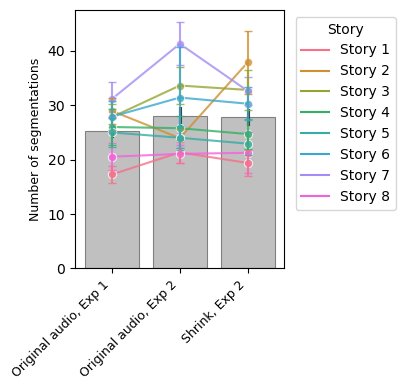

In [24]:
condition_labels = {
    "original": "Original audio, Exp 1",
    "sr_original": "Original audio, Exp 2",
    "shrink": "Shrink, Exp 2",
}
story_labels = {story: str(story_to_idx_mapping[story]) for story in stories}

all_stories_seg_count_df = all_stories_seg_count_df.copy()
all_stories_seg_count_df["condition_label"] = all_stories_seg_count_df["condition"].map(condition_labels)
all_stories_seg_count_df["story_label"] = all_stories_seg_count_df["story"].map(story_labels)

seg_count_stats = (
    all_stories_seg_count_df
    .groupby(["story", "condition"]) ["segmentation_count"]
    .agg(mean="mean", se=lambda x: x.std(ddof=1)/np.sqrt(len(x)))
    .reset_index()
)
seg_count_stats["condition_label"] = seg_count_stats["condition"].map(condition_labels)
seg_count_stats["story_label"] = seg_count_stats["story"].map(story_labels)

# Palette for stories
palette = sns.color_palette("husl", len(stories))
story_colors = dict(zip(stories, palette))

fig, ax = plt.subplots(figsize=(4,4))

sns.barplot(
    data=all_stories_seg_count_df,
    x="condition_label",
    y="segmentation_count",
    order=list(condition_labels.values()),
    errorbar="se",
    color='#C0C0C0',
    edgecolor='#808080',
    linewidth=0.8,
    zorder=1,
    ax=ax
)

sns.lineplot(
    data=seg_count_stats,
    x="condition_label",
    y="mean",
    hue="story_label",
    hue_order=sorted(story_labels.values(), key=int),
    marker="o",
    err_style="bars",
    errorbar=None,
    palette=palette,
    alpha=0.8,
    ax=ax
)

story_label_order = [f"Story {story_to_idx_mapping[s]}" for s in stories]
legend_handles = [
    plt.Line2D([0], [0], color=palette[i], lw=1.5, label=label)
    for i, label in enumerate(story_label_order)
]
ax.legend(handles=legend_handles, title="Story", bbox_to_anchor=(1.02, 1), loc="upper left")

for story, subdf in seg_count_stats.groupby("story"):
    ax.errorbar(
        subdf["condition_label"],
        subdf["mean"],
        yerr=subdf["se"],
        fmt="none",
        ecolor=story_colors[story],
        capsize=3,
        alpha=0.8
    )

ax.set_ylabel("Number of segmentations", fontsize=plot_fontsize)
ax.set_xlabel('')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=plot_fontsize)
#fig.subplots_adjust(left=0.28, right=0.78, bottom=0.22, top=0.92)
plt.tight_layout()
#fig.savefig(os.path.join(fig_dir,'num_segmentations_by_condition.svg'), transparent=True, bbox_inches='tight')
plt.show()


In [25]:
seg_count_stats

,story,condition,mean,se,condition_label,story_label
0,adventuresinsayingyes,original,31.106383,3.201704,"Original audio, Exp 1",7
1,adventuresinsayingyes,shrink,32.590909,2.515138,"Shrink, Exp 2",7
2,adventuresinsayingyes,sr_original,41.254902,3.951157,"Original audio, Exp 2",7
3,alternateithicatom,original,28.937500,2.396882,"Original audio, Exp 1",2
4,alternateithicatom,shrink,37.872340,5.806040,"Shrink, Exp 2",2
5,alternateithicatom,sr_original,23.930233,1.724167,"Original audio, Exp 2",2
6,inamoment,original,20.520833,2.465900,"Original audio, Exp 1",8
7,inamoment,shrink,21.239130,3.793738,"Shrink, Exp 2",8
8,inamoment,sr_original,21.040816,1.705573,"Original audio, Exp 2",8
9,legacy,original,24.980392,2.619308,"Original audio, Exp 1",5


In [26]:
# no effect of condition or interaction on segmentation count
seg_count_lm = ols('segmentation_count~C(story)*C(condition)',data =all_stories_seg_count_df).fit()
table = sm.stats.anova_lm(seg_count_lm, typ=2)
print(table)

                              sum_sq      df         F        PR(>F)
C(story)                30249.147365     7.0  7.792571  3.145670e-09
C(condition)             1246.823223     2.0  1.124192  3.252872e-01
C(story):C(condition)    7960.866635    14.0  1.025411  4.246616e-01
Residual               611105.159522  1102.0       NaN           NaN


## how much does change in segmentation explain about memory? 

### average change in segmentation probability across a window 

In [27]:
def get_uniform_encoding_df(parent_save_dir,uniform_encoding_df_name,model_save_dir_name,split_df = None,sr = False):
    uniform_encoding_dfs = []
    for story in stories:
        uniform_encoding_save_dir = os.path.join(parent_save_dir,model_save_dir_name,'uniform_encoding',story)
        story_uniform_encoding_df = pd.read_csv(os.path.join(uniform_encoding_save_dir,uniform_encoding_df_name))
        story_uniform_encoding_df['story'] = story
        uniform_encoding_dfs.append(story_uniform_encoding_df)
    all_uniform_encoding_dfs = pd.concat(uniform_encoding_dfs,ignore_index = True)
    all_uniform_encoding_dfs = all_uniform_encoding_dfs.rename(columns={'H(event|prev events)': "H_event_conditioned", "H(event)": "H_event"})
    all_uniform_encoding_dfs['story_idx'] = ['Story '+str(story_to_idx_mapping[s]) for s in all_uniform_encoding_dfs['story'].values]
    
    if split_df is not None:
        all_uniform_encoding_dfs['chunk_type'] = ['Boundary' if i else 'Inner' for i in split_df['has_boundary']]
    if sr:
        all_uniform_encoding_dfs['chunk_type_sr'] = ['Boundary' if i else 'Inner' for i in split_df['has_boundary_sr']]
    return all_uniform_encoding_dfs

In [28]:
factor = 1.5
save_dir = '../../generated'
sr_save_dir = '../../exp2/generated'
model_name = 'Llama3-8b-instruct'
model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
model_initial_char = model_to_path_dict[model_name]['initial_char']
if model_name =='Llama3.2-3b-instruct_finetuned':
    tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.2-3B-Instruct")
else:
    tokenizer = AutoTokenizer.from_pretrained(model_to_path_dict[model_name]['hf_name'])

moth_output_dir = os.path.join(save_dir,model_save_dir_name,'moth_stories_output')
plot_fontsize = 8

In [29]:
all_adjusted_split_df_timing_original = []
all_adjusted_split_df_timing_shrink = []
for story in stories:
    save_dir_name = 'story_split_tokens_factor_%.1f_adjusted'%factor
    pairwise_event_save_dir_adjusted = os.path.join(save_dir,model_save_dir_name,'pairwise_event',story,save_dir_name)
    adjusted_split_df_timing_original = pd.read_csv(os.path.join(pairwise_event_save_dir_adjusted,'story_split_by_token_df_adjusted_sr.csv'))
    all_adjusted_split_df_timing_original.append(adjusted_split_df_timing_original)
    
    shrink_story_split_df_save_dir = os.path.join(save_dir,model_save_dir_name,'pairwise_event',story,save_dir_name+'_shrunk')
    adjusted_split_df_timing_shrink = pd.read_csv(os.path.join(shrink_story_split_df_save_dir,'story_split_by_token_df_adjusted.csv'))
    all_adjusted_split_df_timing_shrink.append(adjusted_split_df_timing_shrink)

    
all_adjusted_split_df_timing_original = pd.concat(all_adjusted_split_df_timing_original,ignore_index = True)
all_adjusted_split_df_timing_original['word_count'] = all_adjusted_split_df_timing_original['text'].str.split().str.len()
all_adjusted_split_df_timing_original['word_rate'] = all_adjusted_split_df_timing_original['word_count']/all_adjusted_split_df_timing_original['Duration']
all_adjusted_split_df_timing_original['conditioned_info_per_sec'] = all_adjusted_split_df_timing_original['H_event_conditioned']/all_adjusted_split_df_timing_original['Duration']

# not that this should be a direct copy of the original except for duration related columns. the has_boundary col reflects the consensus of the original experiment, not the updated one
all_adjusted_split_df_timing_shrink = pd.concat(all_adjusted_split_df_timing_shrink,ignore_index = True)
all_adjusted_split_df_timing_shrink['word_count'] = all_adjusted_split_df_timing_shrink['text'].str.split().str.len()
all_adjusted_split_df_timing_shrink['word_rate'] = all_adjusted_split_df_timing_shrink['word_count']/all_adjusted_split_df_timing_shrink['Duration']
all_adjusted_split_df_timing_shrink['conditioned_info_per_sec'] = all_adjusted_split_df_timing_shrink['H_event_conditioned']/all_adjusted_split_df_timing_shrink['Duration']
assert np.all(all_adjusted_split_df_timing_original['H_event_conditioned'].values == all_adjusted_split_df_timing_shrink['H_event_conditioned'])
assert np.all(all_adjusted_split_df_timing_original['word_count']==all_adjusted_split_df_timing_shrink['word_count'])

In [30]:
def get_capacity_preds(parent_save_dir,capacity_model_dict_name,model_save_dir_name):
    all_stories_capacity_model_dict = None
    for story in stories:
        uniform_encoding_save_dir = os.path.join(parent_save_dir,model_save_dir_name,'uniform_encoding',story)
        with open(os.path.join(uniform_encoding_save_dir,capacity_model_dict_name),'rb') as f:
            capacity_model_dict = pickle.load(f)
        exponential_uniform_encoding_dict = capacity_model_dict['exponential_uniform_encoding']
        if not all_stories_capacity_model_dict: # check if empty
            all_stories_capacity_model_dict = {c:[] for c in list(exponential_uniform_encoding_dict.keys())}
        for c in exponential_uniform_encoding_dict.keys():
            all_stories_capacity_model_dict[c].extend(exponential_uniform_encoding_dict[c])
    for c in all_stories_capacity_model_dict.keys():
        all_stories_capacity_model_dict[c] = np.array(all_stories_capacity_model_dict[c])
        
    return all_stories_capacity_model_dict,list(exponential_uniform_encoding_dict.keys())

In [31]:
adjusted = True
if adjusted:
    uniform_encoding_df_basename = 'uniform_encoding_df_even_split_by_tokens_factor_%.1f_adjusted'%factor
    figure_save_dir = os.path.join(sr_save_dir,model_save_dir_name,'uniform_encoding','figures_even_split_by_tokens_factor_%.1f_adjusted'%factor)
    if not os.path.exists(figure_save_dir):
        os.makedirs(figure_save_dir)
else:
    uniform_encoding_df_basename = 'uniform_encoding_df_even_split_by_tokens_factor_%.1f'%factor
uniform_encoding_df_sr_original_name = uniform_encoding_df_basename+'_sr_original.csv'
uniform_encoding_df_sr_shrink_name = uniform_encoding_df_basename+'_sr_shrink.csv'
uniform_encoding_df_exp1_name = uniform_encoding_df_basename+'.csv' # old exp 

uniform_encoding_dfs_original = []
uniform_encoding_dfs_shrink = []
for story in stories:
    uniform_encoding_save_dir = os.path.join(sr_save_dir,model_save_dir_name,'uniform_encoding',story)
    story_uniform_encoding_df_original = pd.read_csv(os.path.join(uniform_encoding_save_dir,uniform_encoding_df_sr_original_name))
    story_uniform_encoding_df_shrink = pd.read_csv(os.path.join(uniform_encoding_save_dir,uniform_encoding_df_sr_shrink_name))
    story_uniform_encoding_df_original['story']=story
    story_uniform_encoding_df_shrink['story']=story
    uniform_encoding_dfs_original.append(story_uniform_encoding_df_original)
    uniform_encoding_dfs_shrink.append(story_uniform_encoding_df_shrink)
all_uniform_encoding_dfs_original = pd.concat(uniform_encoding_dfs_original,ignore_index= True)
all_uniform_encoding_dfs_shrink = pd.concat(uniform_encoding_dfs_shrink,ignore_index= True)

# check that the columns that don't contain recall and duration are the same 
for col in all_uniform_encoding_dfs_original.columns:
    if 'mean' not in col and 'duration' not in col and 'sylber' not in col:
        assert np.all(all_uniform_encoding_dfs_original[col]==all_uniform_encoding_dfs_shrink[col])

all_uniform_encoding_dfs_original=all_uniform_encoding_dfs_original.rename(columns={'H(event|prev events)': "H_event_conditioned", "H(event)": "H_event"})
all_uniform_encoding_dfs_shrink=all_uniform_encoding_dfs_shrink.rename(columns={'H(event|prev events)': "H_event_conditioned", "H(event)": "H_event"})


In [32]:
all_uniform_encoding_dfs_original['chunk_type'] = ['Boundary' if i else 'Inner' for i in all_adjusted_split_df_timing_original['has_boundary']]
all_uniform_encoding_dfs_original['chunk_type_sr'] = ['Boundary' if i else 'Inner' for i in all_adjusted_split_df_timing_original['has_boundary_sr']]
assert np.allclose(all_adjusted_split_df_timing_original['H_event_conditioned'],all_uniform_encoding_dfs_original['H_event_conditioned'])
all_uniform_encoding_dfs_original['story_idx'] = ['Story '+str(story_to_idx_mapping[s]) for s in all_uniform_encoding_dfs_original['story'].values]

all_uniform_encoding_dfs_shrink['chunk_type'] = ['Boundary' if i else 'Inner' for i in all_adjusted_split_df_timing_shrink['has_boundary']]
all_uniform_encoding_dfs_shrink['chunk_type_sr'] = ['Boundary' if i else 'Inner' for i in all_adjusted_split_df_timing_shrink['has_boundary_sr']]

assert np.allclose(all_adjusted_split_df_timing_shrink['H_event_conditioned'],all_uniform_encoding_dfs_shrink['H_event_conditioned'])
all_uniform_encoding_dfs_shrink['story_idx'] = ['Story '+str(story_to_idx_mapping[s]) for s in all_uniform_encoding_dfs_shrink['story'].values]

In [33]:
all_concat_df_original = pd.concat([all_adjusted_split_df_timing_original, all_uniform_encoding_dfs_original], axis=1)
all_concat_df_original = all_concat_df_original.loc[:, ~all_concat_df_original.columns.duplicated()]
all_concat_df_original['condition'] = 'sr_original'

all_concat_df_shrink = pd.concat([all_adjusted_split_df_timing_shrink, all_uniform_encoding_dfs_shrink], axis=1)
all_concat_df_shrink = all_concat_df_shrink.loc[:, ~all_concat_df_shrink.columns.duplicated()]
all_concat_df_shrink['condition'] = 'sr_shrink'
all_concat_dfs = {'original_sr':all_concat_df_original,'shrink_sr':all_concat_df_shrink}

In [34]:
# duration saturation model 
tau_thresh = 2
def get_saturation_duration_pred(uniform_encoding_df_exp1_name,uniform_encoding_df_sr_original_name,uniform_encoding_df_sr_shrink_name,calibration_temp = None):
    all_models_saturation_duration_pred_dict = {}
    model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
    caltemp_suffix = '_caltemp_%.2f'%calibration_temp if calibration_temp is not None else ''
    capacity_model_dict_exp1_name = uniform_encoding_df_exp1_name.replace('uniform_encoding_df', 'duration_exponential_saturation')
    capacity_model_dict_exp1_name = capacity_model_dict_exp1_name.replace('.csv','.pkl')
    
    capacity_model_dict_sr_original_name = uniform_encoding_df_sr_original_name.replace('uniform_encoding_df', 'duration_exponential_saturation')
    capacity_model_dict_sr_original_name = capacity_model_dict_sr_original_name.replace('.csv','.pkl')
    
    capacity_model_dict_sr_shrink_name = uniform_encoding_df_sr_shrink_name.replace('uniform_encoding_df', 'duration_exponential_saturation')
    capacity_model_dict_sr_shrink_name = capacity_model_dict_sr_shrink_name.replace('.csv','.pkl')
    
    capacity_model_dict_exp1,taus = get_capacity_preds(save_dir,capacity_model_dict_exp1_name,model_save_dir_name)
    capacity_model_dict_sr_original,_ = get_capacity_preds(sr_save_dir,capacity_model_dict_sr_original_name,model_save_dir_name)
    capacity_model_dict_sr_shrink,_ = get_capacity_preds(sr_save_dir,capacity_model_dict_sr_shrink_name,model_save_dir_name)

    # only keep tau > tau_thresh?
    capacity_model_dict_exp1 = {k: v for k, v in capacity_model_dict_exp1.items() if k > tau_thresh}
    capacity_model_dict_sr_original = {k: v for k, v in capacity_model_dict_sr_original.items() if k > tau_thresh}
    capacity_model_dict_sr_shrink = {k: v for k, v in capacity_model_dict_sr_shrink.items() if k > tau_thresh}
    taus = [t for t in taus if t > tau_thresh]
    saturation_duration_pred_dict = {'original_exp':capacity_model_dict_exp1,
                                                'original_sr':capacity_model_dict_sr_original,
                                                'shrink_sr':capacity_model_dict_sr_shrink}
    return saturation_duration_pred_dict,taus

In [35]:
saturation_duration_pred_dict,taus =get_saturation_duration_pred(uniform_encoding_df_exp1_name,uniform_encoding_df_sr_original_name,uniform_encoding_df_sr_shrink_name)

In [36]:
metrics_save_dir = os.path.join(save_dir,'metrics')
all_models_best_tau = pd.read_csv(os.path.join(metrics_save_dir,'all_models_best_tau.csv'))

In [37]:
pred = 'weighted_event_info_exponential_saturation'
memory_targets = ['mean_ER_intersect','mean_ER_intersect_recall_last', 'mean_ER_intersect_instruct','mean_ER_intersect_instruct_recall_last']
pred_dict = saturation_duration_pred_dict['original_exp']
pred_dict_shrink = saturation_duration_pred_dict['shrink_sr']
for target in memory_targets:
    split_by_token_best_tau = all_models_best_tau[(all_models_best_tau['model']==model_name) & (all_models_best_tau['target']==target)]['best_tau'].values[0]
    all_concat_dfs['original_sr'][pred+'_'+target] = pred_dict[split_by_token_best_tau]
    all_concat_dfs['shrink_sr'][pred+'_'+target] = pred_dict_shrink[split_by_token_best_tau]

In [38]:
# mean segmentation proportion for each window 
sr_exp_dir = '../../exp2/behavior_data/segmentation'
story_chunk_seg_prop = []
all_stories_chunk_word_indices = {}
for story in stories:
    sr_exp_original_seg_df = pd.read_csv(os.path.join(sr_exp_dir,story,'original','%s_segmentation.csv'%story))
    seg_txt = sr_exp_original_seg_df['original_txt'].iloc[0]
    split_txt = all_adjusted_split_df_timing_original.loc[all_adjusted_split_df_timing_original['story']==story]['text']
    assert (''.join(split_txt)==seg_txt)
    
    with open(os.path.join(sr_exp_dir,story,'original','%s_segmentation_prop.pkl'%story),'rb') as f:
        sr_exp_original_prop = pickle.load(f)
    with open(os.path.join(sr_exp_dir,story,'shrink','%s_segmentation_prop.pkl'%story),'rb') as f:
        sr_exp_shrink_prop = pickle.load(f)
    assert (len(sr_exp_original_prop)==len(seg_txt.split(' ')))
    
    start_end = []# end is exclusive
    chunk_seg_prop_original = []
    chunk_seg_prop_shrink = []
    total_txt_len = 0
    start_idx = 0
    for txt in split_txt:
        if txt.startswith(' '):
            new_txt = txt[1:]
        if txt.endswith(' '):
            new_txt = new_txt[:-1]
        if not (txt.startswith(' ') or txt.endswith(' ')):
            new_txt = txt
        #print(txt)
        txt_len = len(new_txt.split(' '))
        total_txt_len+=txt_len
        end_idx = txt_len+start_idx
        start_end.append([start_idx,end_idx])
        chunk_seg_prop_original.append(sr_exp_original_prop[start_idx:end_idx].mean())
        chunk_seg_prop_shrink.append(sr_exp_shrink_prop[start_idx:end_idx].mean())
        start_idx = end_idx
    assert len(sr_exp_original_prop)==total_txt_len ==end_idx
    story_chunk_seg_prop.append(pd.DataFrame({'original':chunk_seg_prop_original,'shrink':chunk_seg_prop_shrink,'story':story}))
    all_stories_chunk_word_indices[story] = start_end
story_chunk_seg_prop = pd.concat(story_chunk_seg_prop,ignore_index = True)  
story_chunk_seg_prop['chunk_type'] = all_uniform_encoding_dfs_original['chunk_type']
story_chunk_seg_prop['window_id'] = story_chunk_seg_prop.index

all_concat_df_original['seg_prop'] = story_chunk_seg_prop['original']
all_concat_df_shrink['seg_prop'] = story_chunk_seg_prop['shrink']

In [39]:
diff_df = {}
for var in ['mean_ER_intersect','seg_prop','weighted_event_info_by_duration','weighted_event_info_exponential_saturation_mean_ER_intersect','Duration']:
    diff_df[var] = all_concat_df_shrink[var]-all_concat_df_original[var]
diff_df['story'] = all_concat_df_shrink['story']
diff_df = pd.DataFrame(diff_df)

In [40]:
def variance_partioning(r2_dict,base_pred,pred):
    seg_prop_unique = r2_dict[(base_pred,pred)]-r2_dict[pred]
    pred_unique = r2_dict[(base_pred,pred)]-r2_dict[base_pred]
    shared = r2_dict[base_pred]+r2_dict[pred]-r2_dict[(base_pred,pred)]
    print('%s unique: %.2f, %s unique: %.2f, shared: %.2f'%(base_pred,seg_prop_unique,pred,pred_unique,shared))
    return seg_prop_unique,pred_unique,shared

In [41]:
def plot_variance_partitioning(r2_dict_local, p1, p2,plotting_label_dict_sm,save_path=None):
    import matplotlib.pyplot as plt
    import numpy as np

    p1_unique, p2_unique, shared = variance_partioning(r2_dict_local, p1, p2)

    cmap = sns.color_palette("vlag", as_cmap=True)
    color_p1 = sm_colors[p1]   
    color_p2 = sm_colors[p2]
    # color_p1 = cmap(0.15)   # blue side
    color_shared = cmap(0.5)  # neutral center
    # color_p2 = cmap(0.85)   # red side
    x = 0  # single column position

    plt.figure(figsize=(1, 3))

    plt.bar(x, p1_unique, width=0.6, color=color_p1, alpha = 0.6,label=f"{plotting_label_dict_sm[p1]} unique")
    plt.bar(x, shared, bottom=p1_unique, width=0.6, alpha = 0.6,color=color_shared, label="Shared")
    plt.bar(x, p2_unique, bottom=p1_unique + shared, width=0.6, alpha = 0.6,color=color_p2, label=f"{plotting_label_dict_sm[p2]} unique")

    
    # Optional internal labels
    plt.text(x, p1_unique/2, f"{p1_unique:.2f}", ha='center', va='center', color='black')
    plt.text(x, p1_unique + shared/2, f"{shared:.2f}", ha='center', va='center', color='black')
    plt.text(x, p1_unique + shared + p2_unique/2, f"{p2_unique:.2f}", ha='center', va='center', color='black')

    plt.xticks([x], [""])
    plt.ylabel("R²")
    plt.title("Variance explained",fontsize=plot_fontsize)

    plt.ylim(0, p1_unique + p2_unique + shared * 1.05)

    plt.legend(
        frameon=False,
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        fontsize = plot_fontsize
    )
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, transparent = True)
    plt.show()


In [42]:
# variance partitioning
r2_dict = {}
for pred in ['seg_prop','weighted_event_info_by_duration','weighted_event_info_exponential_saturation_mean_ER_intersect','Duration']:
    fit = ols('mean_ER_intersect ~ %s+%s:C(story)'%(pred,pred), data=diff_df).fit() 
    if 'saturation' in pred:
        pred_name = 'weighted_event_info_exponential_saturation'
    else:
        pred_name = pred
    r2_dict[pred_name] = fit.rsquared
for pred in ['weighted_event_info_by_duration','weighted_event_info_exponential_saturation_mean_ER_intersect','Duration']:
    # full model
    fit = ols('mean_ER_intersect ~ seg_prop+seg_prop:C(story)+%s+%s:C(story)'%(pred,pred), data=diff_df).fit() 
    if 'saturation' in pred:
        pred_name = 'weighted_event_info_exponential_saturation'
    else:
        pred_name = pred
    r2_dict[('seg_prop',pred_name)] = fit.rsquared

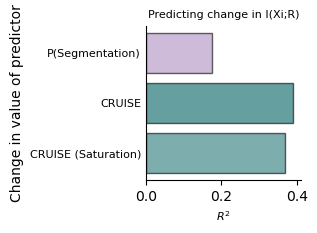

In [43]:
sm_colors = {}
sm_colors['weighted_event_info_by_duration'] = all_colors['weighted_event_info_by_duration']
sm_colors['weighted_event_info_exponential_saturation'] = all_colors['weighted_event_info_exponential_saturation']
sm_colors['Duration'] = all_colors['event_duration']
sm_colors['seg_prop'] = all_colors['chunk_type']

pred_labels = [plotting_label_dict_sm[p] for p in ['seg_prop','weighted_event_info_by_duration','weighted_event_info_exponential_saturation']]
plot_df = []
for pred in ['seg_prop','weighted_event_info_by_duration','weighted_event_info_exponential_saturation']:
    plot_df.append([pred,plotting_label_dict_sm[pred],r2_dict[pred]])

plot_df = pd.DataFrame(plot_df,columns = ['pred','pred_labels','r2'])


colors = [sm_colors[p] for p in plot_df['pred']]
fig,ax = plt.subplots(figsize = (2,2))
bars = ax.barh(plot_df['pred_labels'][::-1], plot_df['r2'][::-1],  color=colors[::-1], edgecolor='black',alpha = 0.6)
#ax.set_title(model_plotting_names[model],fontsize =17)
ax.set_yticks(plot_df['pred_labels'][::-1])
ax.set_yticklabels(plot_df['pred_labels'][::-1],fontsize = plot_fontsize)
ax.set_xlabel(r'$R^2$',fontsize = plot_fontsize)
ax.set_title('Predicting change in I(Xi;R)',fontsize=plot_fontsize)
ax.set_ylabel('Change in value of predictor')
sns.despine()
ax.tick_params(axis='y', length=0) # hides ticks 
#fig.savefig(os.path.join(fig_dir,'predict_change_in_memory.svg'),transparent=True)
plt.show()


In [44]:
plot_df

,pred,pred_labels,r2
0,seg_prop,P(Segmentation),0.175712
1,weighted_event_info_by_duration,CRUISE,0.391233
2,weighted_event_info_exponential_saturation,CRUISE (Saturation),0.369853


In [45]:
variance_partioning(r2_dict,'seg_prop','weighted_event_info_by_duration')

seg_prop unique: 0.02, weighted_event_info_by_duration unique: 0.24, shared: 0.15


(np.float64(0.023615288732172335),
 np.float64(0.23913571291613955),
 np.float64(0.1520970973860537))

seg_prop unique: 0.02, weighted_event_info_by_duration unique: 0.24, shared: 0.15


/tmp/ipykernel_2548805/1871937339.py:39: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


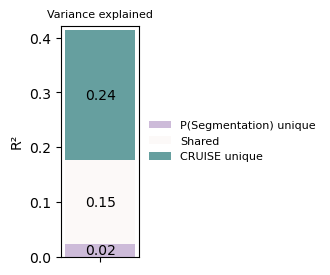

In [46]:
save_path = os.path.join(fig_dir,'variance_partitioning_seg_prop_cruise.svg')
plot_variance_partitioning(r2_dict,'seg_prop','weighted_event_info_by_duration',plotting_label_dict_sm,save_path=save_path)

In [47]:
variance_partioning(r2_dict,'seg_prop','weighted_event_info_exponential_saturation')

seg_prop unique: 0.02, weighted_event_info_exponential_saturation unique: 0.22, shared: 0.15


(np.float64(0.020874662853938797),
 np.float64(0.2150148142908216),
 np.float64(0.15483772326428724))

seg_prop unique: 0.02, weighted_event_info_exponential_saturation unique: 0.22, shared: 0.15


/tmp/ipykernel_2548805/1871937339.py:39: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


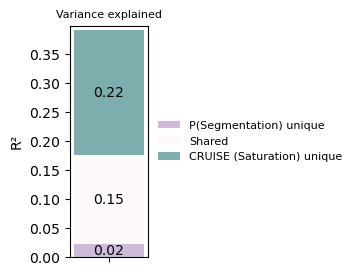

In [48]:
save_path = os.path.join(fig_dir,'variance_partitioning_seg_prop_cruise_saturation.svg')
plot_variance_partitioning(r2_dict,'seg_prop','weighted_event_info_exponential_saturation',plotting_label_dict_sm,save_path=save_path)